<a href="https://colab.research.google.com/github/SeratAftab/Irreversible-Vision-Loss/blob/main/Irreversible_Vision_Loss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set up and Mount

In [ ]:

import os, gc, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mob_pre
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_pre
from tensorflow.keras.applications.densenet import preprocess_input as den_pre
from tensorflow.keras.applications.resnet50 import preprocess_input as res_pre
from sklearn.model_selection import train_test_split
from google.colab import drive
drive.mount('/content/drive')

pre_dir  = '/content/drive/MyDrive/Thesis/preprocessed_images'
csv_path = '/content/drive/MyDrive/Thesis/full_df.csv'
save_dir = '/content/drive/MyDrive/Thesis/saved_models'
cols = ['N','D','G','C','A','H','M','O']
BS = 16

df = pd.read_csv(csv_path)
df['patient'] = df['filename'].str.split('_').str[0]
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['D'])
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
in_train = val_df.patient.isin(set(train_df.patient)).values
print(f"Val images with a patient also in train: {in_train.sum()}/{len(val_df)}  | clean (no overlap): {(~in_train).sum()}")

def batches():
    for i in range(0, len(val_df), BS):
        fns = val_df.filename.values[i:i+BS]
        yield np.stack([keras_image.img_to_array(
            keras_image.load_img(os.path.join(pre_dir, f), target_size=(224,224))) for f in fns]).astype(np.float32)

def run_single(name, fn, pre):
    path = f'{save_dir}/valprob_{name}.npy'
    if os.path.exists(path): print(name, 'cached'); return
    m = load_model(f'{save_dir}/{fn}', compile=False)
    p = [m(x/255.0 if pre is None else pre(x.copy()), training=False).numpy() for x in batches()]
    np.save(path, np.concatenate(p)); print(name, 'done')
    del m; tf.keras.backend.clear_session(); gc.collect()

for name, fn, pre in [('MobileNetV2','mobilenet_final.keras',None),
                      ('EfficientNetB0','efficientnet_v2_final.keras',eff_pre),
                      ('DenseNet121','densenet_final.keras',den_pre),
                      ('ResNet50','resnet_final.keras',res_pre)]:
    run_single(name, fn, pre)

path = f'{save_dir}/valprob_C8_fusion.npy'
if not os.path.exists(path):
    c8 = load_model(f'{save_dir}/C8_final.keras', compile=False)
    p = [c8([mob_pre(x.copy()), eff_pre(x.copy()), den_pre(x.copy()), res_pre(x.copy())], training=False).numpy()
         for x in batches()]
    np.save(path, np.concatenate(p)); print('C8_fusion done')
    del c8; tf.keras.backend.clear_session(); gc.collect()

names = ['MobileNetV2','EfficientNetB0','DenseNet121','ResNet50','C8_fusion']
np.savez(f'{save_dir}/val_probs.npz', y_true=val_df[cols].values.astype(np.float32),
         patient=val_df.patient.values, filename=val_df.filename.values, in_train=in_train,
         **{n: np.load(f'{save_dir}/valprob_{n}.npy') for n in names})
print('Saved val_probs.npz')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Val images with a patient also in train: 960/1279  | clean (no overlap): 319
MobileNetV2 done
EfficientNetB0 done
DenseNet121 done
ResNet50 done
C8_fusion done
Saved val_probs.npz


# Rerunning the models

In [ ]:

import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, roc_auc_score

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
POS = ['G', 'A', 'M']
COLS = ['N','D','G','C','A','H','M','O']
SEED, N_BOOT, N_REPEATS = 42, 2000, 30
pos_idx = [COLS.index(c) for c in POS]

d = np.load(NPZ, allow_pickle=True)
Y, pat = d['y_true'], d['patient']
clean = ~d['in_train']
y = (Y[:, pos_idx].max(1) > 0).astype(int)
MODELS = [k for k in d.files if k not in ('y_true', 'patient', 'filename', 'in_train')]
print(f"Positive ('{'/'.join(POS)}') prevalence: {y.mean():.3f}  ({y.sum()}/{len(y)})")
print(f"Majority-class accuracy baseline: {1-y.mean():.4f}\n")

def score_max(P):  return P[:, pos_idx].max(1)
def score_nor(P):  return 1 - np.prod(1 - P[:, pos_idx], axis=1)

def best_thr(s, yt):
    grid = np.arange(0.05, 0.96, 0.01)
    f = [f1_score(yt, s >= t, zero_division=0) for t in grid]
    return grid[int(np.argmax(f))]

def metrics(yt, s, t):
    yp = (s >= t).astype(int)
    return dict(F1=f1_score(yt, yp, zero_division=0), Acc=accuracy_score(yt, yp),
                Prec=precision_score(yt, yp, zero_division=0), Rec=recall_score(yt, yp),
                AUC=roc_auc_score(yt, s))

def split(seed):
    sk = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=seed)
    return next(sk.split(np.zeros(len(y)), y, groups=pat))

def run(seed):
    tune, test = split(seed)
    res = {}
    for m in MODELS:
        P = d[m]
        for rule, fn in (('max', score_max), ('noisyOR', score_nor)):
            s = fn(P); t = best_thr(s[tune], y[tune])
            res[(m, rule)] = (metrics(y[test], s[test], t), t, s[test])
        lr = LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced').fit(P[tune], y[tune])
        s = lr.predict_proba(P)[:, 1]; t = best_thr(s[tune], y[tune])
        res[(m, 'stacked')] = (metrics(y[test], s[test], t), t, s[test])
    return res, test


tune_i, test_i = np.where(~clean)[0], np.where(clean)[0]
print(f"=== CLEAN TEST: n={len(test_i)} images, {len(np.unique(pat[test_i]))} patients, positives={y[test_i].sum()} "
      f"| majority-baseline acc={1-y[test_i].mean():.4f} ===")
rng0 = np.random.default_rng(SEED); pt0 = pat[test_i]; up0 = np.unique(pt0); by0 = {p: np.where(pt0 == p)[0] for p in up0}
rows = []
for m in MODELS:
    P = d[m]
    lr = LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced').fit(P[tune_i], y[tune_i])
    for rule, s_all in (('max', score_max(P)), ('noisyOR', score_nor(P)), ('stacked', lr.predict_proba(P)[:, 1])):
        t = best_thr(s_all[tune_i], y[tune_i]); mt = metrics(y[test_i], s_all[test_i], t)
        f1s, accs = [], []
        for _ in range(N_BOOT):
            ii = np.concatenate([by0[p] for p in rng0.choice(up0, len(up0))])
            yp = (s_all[test_i][ii] >= t).astype(int); yt = y[test_i][ii]
            f1s.append(f1_score(yt, yp, zero_division=0)); accs.append(accuracy_score(yt, yp))
        rows.append(dict(Model=m, Rule=rule, Thr=round(t, 2), **{k: round(v, 4) for k, v in mt.items()},
                         F1_CI=f"[{np.percentile(f1s,2.5):.3f},{np.percentile(f1s,97.5):.3f}]",
                         Acc_CI=f"[{np.percentile(accs,2.5):.3f},{np.percentile(accs,97.5):.3f}]"))
ctab = pd.DataFrame(rows).sort_values('F1', ascending=False)
print(ctab.to_string(index=False))
ctab.to_csv('/content/drive/MyDrive/Thesis/saved_models/binary_screen_CLEAN_test.csv', index=False)
print("\nBelow: the same analysis on ALL val images (patients overlap with train -> optimistic). Compare to quantify leakage.\n")
res, test = run(SEED)
rng = np.random.default_rng(SEED)
pt = pat[test]; upat = np.unique(pt); idx_by = {p: np.where(pt == p)[0] for p in upat}
rows = []
for (m, rule), (mt, t, s) in res.items():
    f1s, accs = [], []
    for _ in range(N_BOOT):
        ii = np.concatenate([idx_by[p] for p in rng.choice(upat, len(upat))])
        yp = (s[ii] >= t).astype(int); yt = y[test][ii]
        f1s.append(f1_score(yt, yp, zero_division=0)); accs.append(accuracy_score(yt, yp))
    rows.append(dict(Model=m, Rule=rule, Thr=round(t, 2), **{k: round(v, 4) for k, v in mt.items()},
                     F1_CI=f"[{np.percentile(f1s,2.5):.3f},{np.percentile(f1s,97.5):.3f}]",
                     Acc_CI=f"[{np.percentile(accs,2.5):.3f},{np.percentile(accs,97.5):.3f}]"))
tab = pd.DataFrame(rows).sort_values('F1', ascending=False)
print(f"=== ALL-VAL half, optimistic (seed {SEED}, n={len(test)}, positives={y[test].sum()}) ===")
print(f"Majority baseline acc on this half: {1-y[test].mean():.4f}")
print(tab.to_string(index=False))

agg = {}
for r in range(N_REPEATS):
    rr, _ = run(1000 + r)
    for k, (mt, _, _) in rr.items():
        agg.setdefault(k, []).append((mt['F1'], mt['Acc']))
st = pd.DataFrame([dict(Model=k[0], Rule=k[1], F1_mean=np.mean([a for a,_ in v]), F1_sd=np.std([a for a,_ in v]),
                        Acc_mean=np.mean([b for _,b in v]), Acc_sd=np.std([b for _,b in v]))
                   for k, v in agg.items()]).sort_values('F1_mean', ascending=False).round(4)
print(f"\n=== ALL-VAL stability (optimistic) over {N_REPEATS} random patient-grouped 50/50 splits ===")
print(st.to_string(index=False))
tab.to_csv('/content/drive/MyDrive/Thesis/saved_models/binary_screen_heldout.csv', index=False)
st.to_csv('/content/drive/MyDrive/Thesis/saved_models/binary_screen_stability.csv', index=False)

Positive ('G/A/M') prevalence: 0.160  (205/1279)
Majority-class accuracy baseline: 0.8397

=== CLEAN TEST: n=319 images, 200 patients, positives=62 | majority-baseline acc=0.8056 ===
         Model    Rule  Thr     F1    Acc   Prec    Rec    AUC         F1_CI        Acc_CI
     C8_fusion noisyOR 0.46 0.6446 0.8652 0.6610 0.6290 0.8790 [0.524,0.738] [0.821,0.906]
     C8_fusion     max 0.46 0.6387 0.8652 0.6667 0.6129 0.8806 [0.520,0.738] [0.820,0.907]
   DenseNet121 noisyOR 0.48 0.6207 0.8621 0.6667 0.5806 0.8627 [0.505,0.727] [0.815,0.905]
   DenseNet121     max 0.47 0.6140 0.8621 0.6731 0.5645 0.8620 [0.491,0.721] [0.816,0.905]
EfficientNetB0 stacked 0.71 0.6087 0.8589 0.6604 0.5645 0.8633 [0.490,0.708] [0.816,0.900]
      ResNet50 stacked 0.79 0.6078 0.8746 0.7750 0.5000 0.8457 [0.476,0.723] [0.828,0.915]
   DenseNet121 stacked 0.76 0.6055 0.8652 0.7021 0.5323 0.8798 [0.483,0.716] [0.819,0.908]
      ResNet50     max 0.45 0.5981 0.8652 0.7111 0.5161 0.8475 [0.462,0.711] [0.820,0.907

# Evaluation

In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
OUT = '/content/drive/MyDrive/Thesis/saved_models/final_binary_tables.csv'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
ORDER = ['MobileNetV2', 'EfficientNetB0', 'DenseNet121', 'ResNet50', 'C8_fusion']
idx = [COLS.index(c) for c in POS]

d = np.load(NPZ, allow_pickle=True)
y = (d['y_true'][:, idx].max(1) > 0).astype(int); pat = d['patient']; clean = ~d['in_train']
grid = np.arange(0.05, 0.96, 0.01)
def best_thr(s, yt): return grid[int(np.argmax([f1_score(yt, s >= t, zero_division=0) for t in grid]))]

def table(tune, test, title):
    rows = []
    for m in ORDER:
        s = d[m][:, idx].max(1); t = best_thr(s[tune], y[tune]); yp = (s[test] >= t).astype(int)
        rows.append({'Model': m.replace('_fusion', ' (Fusion)'), 'Accuracy': accuracy_score(y[test], yp),
                     'Precision': precision_score(y[test], yp, zero_division=0),
                     'Recall': recall_score(y[test], yp), 'F1': f1_score(y[test], yp, zero_division=0)})
    print(f"\n{title}\nn={len(test)}, positives={y[test].sum()} ({y[test].mean():.1%}), "
          f"always-safe baseline accuracy={1-y[test].mean():.3f}")
    out = pd.DataFrame(rows).round(3); print(out.to_string(index=False)); return out.assign(Table=title)

t1 = table(np.where(~clean)[0], np.where(clean)[0], "CLEAN TEST (no patient overlap with training)")
a, b = next(StratifiedGroupKFold(2, shuffle=True, random_state=42).split(np.zeros(len(y)), y, groups=pat))
t2 = table(a, b, "ALL-VAL SPLIT (optimistic: patients overlap with training)")
pd.concat([t1, t2]).to_csv(OUT, index=False); print("\nSaved", OUT)


CLEAN TEST (no patient overlap with training)
n=319, positives=62 (19.4%), always-safe baseline accuracy=0.806
         Model  Accuracy  Precision  Recall    F1
   MobileNetV2     0.840      0.667   0.355 0.463
EfficientNetB0     0.831      0.571   0.516 0.542
   DenseNet121     0.862      0.673   0.565 0.614
      ResNet50     0.865      0.711   0.516 0.598
   C8 (Fusion)     0.865      0.667   0.613 0.639

ALL-VAL SPLIT (optimistic: patients overlap with training)
n=643, positives=104 (16.2%), always-safe baseline accuracy=0.838
         Model  Accuracy  Precision  Recall    F1
   MobileNetV2     0.886      0.754   0.442 0.558
EfficientNetB0     0.880      0.652   0.558 0.601
   DenseNet121     0.886      0.657   0.625 0.640
      ResNet50     0.886      0.701   0.519 0.597
   C8 (Fusion)     0.885      0.625   0.721 0.670

Saved /content/drive/MyDrive/Thesis/saved_models/final_binary_tables.csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Overall positive rate 0.160 | clean test: n=319, positives=62 (19.4%), always-safe baseline accuracy=0.806


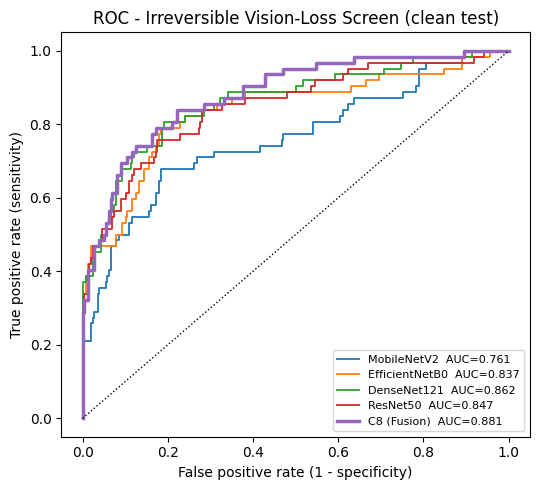

In [ ]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix, f1_score, accuracy_score,
                             recall_score, precision_score)
from sklearn.tree import DecisionTreeClassifier, export_text
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
DIR = '/content/drive/MyDrive/Thesis/saved_models/'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
ORDER = ['MobileNetV2', 'EfficientNetB0', 'DenseNet121', 'ResNet50', 'C8_fusion']
idx = [COLS.index(c) for c in POS]; N_BOOT = 2000; SEED = 42

d = np.load(NPZ, allow_pickle=True)
y = (d['y_true'][:, idx].max(1) > 0).astype(int); pat = d['patient']; clean = ~d['in_train']
tune, test = np.where(~clean)[0], np.where(clean)[0]
S = {m: d[m][:, idx].max(1) for m in ORDER}
grid = np.arange(0.01, 1.0, 0.01)
def best_thr(s, yt): return grid[int(np.argmax([f1_score(yt, s >= t, zero_division=0) for t in grid]))]
def sens_spec(yt, yp):
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel(); return tp/(tp+fn), tn/(tn+fp)
THR = {m: best_thr(S[m][tune], y[tune]) for m in ORDER}
print(f"Overall positive rate {y.mean():.3f} | clean test: n={len(test)}, positives={y[test].sum()} ({y[test].mean():.1%}), "
      f"always-safe baseline accuracy={1-y[test].mean():.3f}")

plt.figure(figsize=(5.5, 5))
for m in ORDER:
    fpr, tpr, _ = roc_curve(y[test], S[m][test]); plt.plot(fpr, tpr, lw=2.5 if m == 'C8_fusion' else 1.3,
        label=f"{m.replace('_fusion',' (Fusion)')}  AUC={roc_auc_score(y[test], S[m][test]):.3f}")
plt.plot([0, 1], [0, 1], 'k:', lw=1); plt.xlabel('False positive rate (1 - specificity)'); plt.ylabel('True positive rate (sensitivity)')
plt.title('ROC - Irreversible Vision-Loss Screen (clean test)'); plt.legend(loc='lower right', fontsize=8); plt.tight_layout()
plt.savefig(DIR + 'roc_clean.png', dpi=150); plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Overall positive rate 0.160 | clean test: n=319, positives=62 (19.4%), always-safe baseline accuracy=0.806


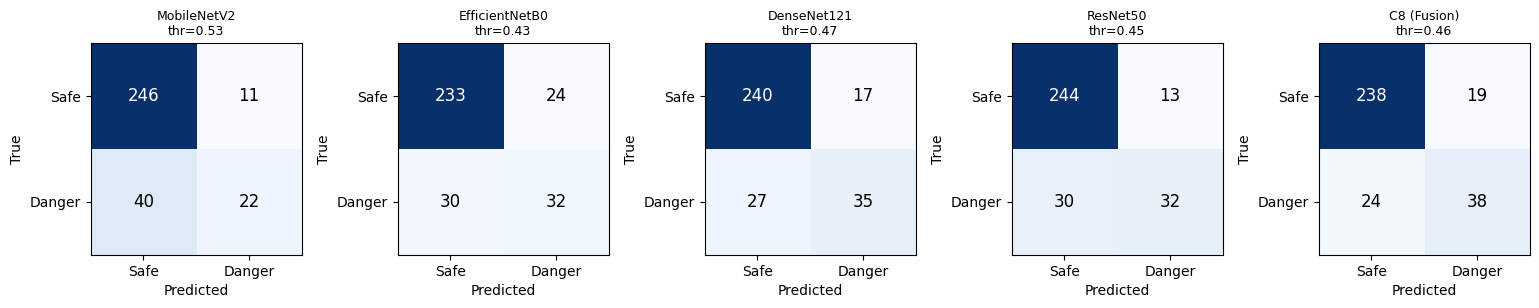

In [ ]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix, f1_score, accuracy_score,
                             recall_score, precision_score)
from sklearn.tree import DecisionTreeClassifier, export_text
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
DIR = '/content/drive/MyDrive/Thesis/saved_models/'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
ORDER = ['MobileNetV2', 'EfficientNetB0', 'DenseNet121', 'ResNet50', 'C8_fusion']
idx = [COLS.index(c) for c in POS]; N_BOOT = 2000; SEED = 42

d = np.load(NPZ, allow_pickle=True)
y = (d['y_true'][:, idx].max(1) > 0).astype(int); pat = d['patient']; clean = ~d['in_train']
tune, test = np.where(~clean)[0], np.where(clean)[0]
S = {m: d[m][:, idx].max(1) for m in ORDER}
grid = np.arange(0.01, 1.0, 0.01)
def best_thr(s, yt): return grid[int(np.argmax([f1_score(yt, s >= t, zero_division=0) for t in grid]))]
def sens_spec(yt, yp):
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel(); return tp/(tp+fn), tn/(tn+fp)
THR = {m: best_thr(S[m][tune], y[tune]) for m in ORDER}
print(f"Overall positive rate {y.mean():.3f} | clean test: n={len(test)}, positives={y[test].sum()} ({y[test].mean():.1%}), "
      f"always-safe baseline accuracy={1-y[test].mean():.3f}")

fig, ax = plt.subplots(1, len(ORDER), figsize=(3.1 * len(ORDER), 3.2))
for a_, m in zip(ax, ORDER):
    cm = confusion_matrix(y[test], S[m][test] >= THR[m], labels=[0, 1])
    a_.imshow(cm, cmap='Blues'); a_.set_title(f"{m.replace('_fusion',' (Fusion)')}\nthr={THR[m]:.2f}", fontsize=9)
    a_.set_xticks([0, 1], ['Safe', 'Danger']); a_.set_yticks([0, 1], ['Safe', 'Danger']); a_.set_xlabel('Predicted'); a_.set_ylabel('True')
    for i in range(2):
        for j in range(2): a_.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=12)
plt.tight_layout(); plt.savefig(DIR + 'confusion_clean.png', dpi=150); plt.show()

In [ ]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix, f1_score, accuracy_score,
                             recall_score, precision_score)
from sklearn.tree import DecisionTreeClassifier, export_text
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
DIR = '/content/drive/MyDrive/Thesis/saved_models/'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
ORDER = ['MobileNetV2', 'EfficientNetB0', 'DenseNet121', 'ResNet50', 'C8_fusion']
idx = [COLS.index(c) for c in POS]; N_BOOT = 2000; SEED = 42

d = np.load(NPZ, allow_pickle=True)
y = (d['y_true'][:, idx].max(1) > 0).astype(int); pat = d['patient']; clean = ~d['in_train']
tune, test = np.where(~clean)[0], np.where(clean)[0]
S = {m: d[m][:, idx].max(1) for m in ORDER}
grid = np.arange(0.01, 1.0, 0.01)
def best_thr(s, yt): return grid[int(np.argmax([f1_score(yt, s >= t, zero_division=0) for t in grid]))]
def sens_spec(yt, yp):
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel(); return tp/(tp+fn), tn/(tn+fp)
THR = {m: best_thr(S[m][tune], y[tune]) for m in ORDER}
print(f"Overall positive rate {y.mean():.3f} | clean test: n={len(test)}, positives={y[test].sum()} ({y[test].mean():.1%}), "
      f"always-safe baseline accuracy={1-y[test].mean():.3f}")

def thr_for(s, yt, kind, target):
    best = None
    for t in grid:
        se, sp = sens_spec(yt, (s >= t).astype(int))
        if kind == 'sens' and se >= target: best = t
        if kind == 'spec' and sp >= target and best is None: best = t
    return best if best is not None else grid[0 if kind == 'sens' else -1]
rows = []
for m in ORDER:
    for kind, target in (('sens', .90), ('sens', .85), ('spec', .90)):
        t = thr_for(S[m][tune], y[tune], kind, target); yp = (S[m][test] >= t).astype(int); se, sp = sens_spec(y[test], yp)
        rows.append({'Model': m.replace('_fusion', ' (Fusion)'), 'Target': f"{int(target*100)}% {'sensitivity' if kind=='sens' else 'specificity'}",
                     'Thr': round(t, 2), 'Sensitivity': se, 'Specificity': sp, 'Precision': precision_score(y[test], yp, zero_division=0),
                     'Accuracy': accuracy_score(y[test], yp)})
op = pd.DataFrame(rows).round(3); print(op.to_string(index=False)); op.to_csv(DIR + 'operating_points.csv', index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Overall positive rate 0.160 | clean test: n=319, positives=62 (19.4%), always-safe baseline accuracy=0.806
         Model          Target  Thr  Sensitivity  Specificity  Precision  Accuracy
   MobileNetV2 90% sensitivity 0.04        0.806        0.440      0.258     0.511
   MobileNetV2 85% sensitivity 0.07        0.726        0.584      0.296     0.611
   MobileNetV2 90% specificity 0.31        0.500        0.895      0.534     0.818
EfficientNetB0 90% sensitivity 0.10        0.871        0.634      0.365     0.680
EfficientNetB0 85% sensitivity 0.17        0.806        0.770      0.459     0.777
EfficientNetB0 90% specificity 0.34        0.597        0.883      0.552     0.828
   DenseNet121 90% sensitivity 0.05        0.887        0.537      0.316     0.605
   DenseNet121 85% sensitivity 0.07        0.887        0.646      0.377     0.693
   DenseNet121 90

# Risk tiers

In [ ]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix, f1_score, accuracy_score,
                             recall_score, precision_score)
from sklearn.tree import DecisionTreeClassifier, export_text
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
DIR = '/content/drive/MyDrive/Thesis/saved_models/'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
ORDER = ['MobileNetV2', 'EfficientNetB0', 'DenseNet121', 'ResNet50', 'C8_fusion']
idx = [COLS.index(c) for c in POS]; N_BOOT = 2000; SEED = 42

d = np.load(NPZ, allow_pickle=True)
y = (d['y_true'][:, idx].max(1) > 0).astype(int); pat = d['patient']; clean = ~d['in_train']
tune, test = np.where(~clean)[0], np.where(clean)[0]
S = {m: d[m][:, idx].max(1) for m in ORDER}
grid = np.arange(0.01, 1.0, 0.01)
def best_thr(s, yt): return grid[int(np.argmax([f1_score(yt, s >= t, zero_division=0) for t in grid]))]
def sens_spec(yt, yp):
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel(); return tp/(tp+fn), tn/(tn+fp)
THR = {m: best_thr(S[m][tune], y[tune]) for m in ORDER}
print(f"Overall positive rate {y.mean():.3f} | clean test: n={len(test)}, positives={y[test].sum()} ({y[test].mean():.1%}), "
      f"always-safe baseline accuracy={1-y[test].mean():.3f}")

def thr_for(s, yt, kind, target):
    best = None
    for t in grid:
        se, sp = sens_spec(yt, (s >= t).astype(int))
        if kind == 'sens' and se >= target: best = t
        if kind == 'spec' and sp >= target and best is None: best = t
    return best if best is not None else grid[0 if kind == 'sens' else -1]


s = S['C8_fusion']; t_hi = THR['C8_fusion']; t_lo = min(thr_for(s[tune], y[tune], 'sens', .95), t_hi)
tier = np.where(s[test] >= t_hi, 'High', np.where(s[test] >= t_lo, 'Medium', 'Low'))
rt = pd.DataFrame({'Tier': ['Low', 'Medium', 'High']})
rt['Score range'] = [f"< {t_lo:.2f}", f"{t_lo:.2f} - {t_hi:.2f}", f">= {t_hi:.2f}"]
rt['Patients'] = [(tier == k).sum() for k in rt.Tier]; rt['Share'] = (rt.Patients / len(test)).round(3)
rt['Actual dangerous'] = [y[test][tier == k].sum() for k in rt.Tier]; rt['Observed risk'] = (rt['Actual dangerous'] / rt.Patients.replace(0, np.nan)).round(3)
print("Low = below the 95%-sensitivity cutoff; High = at/above the F1-optimal cutoff\n"); print(rt.to_string(index=False))
rt.to_csv(DIR + 'risk_tiers.csv', index=False)

Mounted at /content/drive
Overall positive rate 0.160 | clean test: n=319, positives=62 (19.4%), always-safe baseline accuracy=0.806
Low = below the 95%-sensitivity cutoff; High = at/above the F1-optimal cutoff

  Tier Score range  Patients  Share  Actual dangerous  Observed risk
   Low      < 0.01        88  0.276                 1          0.011
Medium 0.01 - 0.46       174  0.545                23          0.132
  High     >= 0.46        57  0.179                38          0.667


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cutoffs (from tuning images): Low < 0.0098 <= Medium < 0.575 <= High

=== Risk tiers on the clean test (n=319, 62 dangerous) ===
  Tier  Suggested action  Patients  Share  Dangerous  Observed risk  Risk 95% CI  Share of all dangerous
   Low Routine follow-up        87  0.273          1          0.011 [0.00, 0.06]                   0.016
Medium  Clinician review       182  0.571         27          0.148 [0.10, 0.21]                   0.435
  High   Urgent referral        50  0.157         34          0.680 [0.54, 0.79]                   0.548

=== Disease that drives the score, by tier (counts) ===
Driver    A   G   M
Tier               
Low      59  24   4
Medium  113  61   8
High     12  22  16

=== True diseases among dangerous patients, by tier (a patient can have more than one) ===
         G  A   M
Low      1  0   0
Medium  14  7   8
High    14  6  17


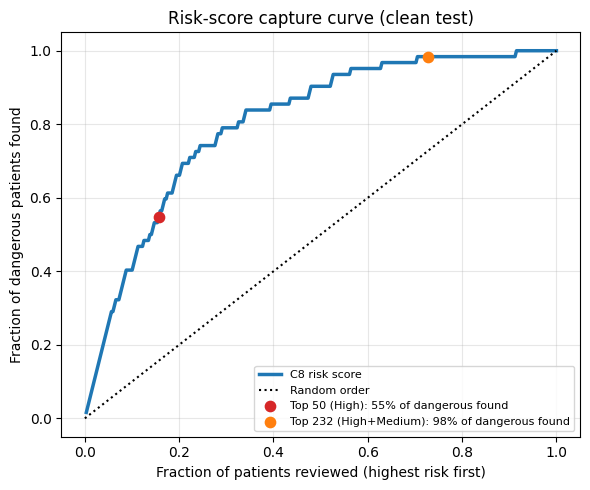

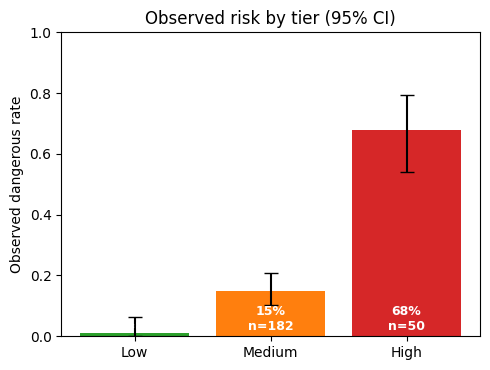

In [ ]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
DIR = '/content/drive/MyDrive/Thesis/saved_models/'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
idx = [COLS.index(c) for c in POS]
LOW_SENS = 0.95

d = np.load(NPZ, allow_pickle=True)
y = (d['y_true'][:, idx].max(1) > 0).astype(int); clean = ~d['in_train']
tune, test = np.where(~clean)[0], np.where(clean)[0]
P = d['C8_fusion'][:, idx]; s = P.max(1); drv = np.array(POS)[P.argmax(1)]

grid = np.unique(np.concatenate([np.geomspace(1e-4, 0.5, 250), np.linspace(0.5, 0.99, 60)]))
t_hi = grid[int(np.argmax([f1_score(y[tune], s[tune] >= t, zero_division=0) for t in grid]))]
ok = [t for t in grid if (s[tune][y[tune] == 1] >= t).mean() >= LOW_SENS]
t_lo = min(max(ok) if ok else grid[0], t_hi)
print(f"Cutoffs (from tuning images): Low < {t_lo:.4f} <= Medium < {t_hi:.3f} <= High")

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z*z/n; c = (p + z*z/(2*n)) / den; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return c - h, c + h

st, yt, dt = s[test], y[test], drv[test]
tier = np.where(st >= t_hi, 'High', np.where(st >= t_lo, 'Medium', 'Low'))
rows = []
for k, act in (('Low', 'Routine follow-up'), ('Medium', 'Clinician review'), ('High', 'Urgent referral')):
    m = tier == k; n, pos = int(m.sum()), int(yt[m].sum()); lo, hi = wilson(pos, n)
    rows.append({'Tier': k, 'Suggested action': act, 'Patients': n, 'Share': round(n/len(test), 3), 'Dangerous': pos,
                 'Observed risk': round(pos/n, 3) if n else np.nan, 'Risk 95% CI': f"[{lo:.2f}, {hi:.2f}]",
                 'Share of all dangerous': round(pos/yt.sum(), 3)})
tab = pd.DataFrame(rows); print("\n=== Risk tiers on the clean test (n=%d, %d dangerous) ===" % (len(test), yt.sum())); print(tab.to_string(index=False))
tab.to_csv(DIR + 'risk_tiers_v2.csv', index=False)

print("\n=== Disease that drives the score, by tier (counts) ===")
print(pd.crosstab(pd.Series(tier, name='Tier'), pd.Series(dt, name='Driver')).reindex(['Low', 'Medium', 'High']).to_string())
print("\n=== True diseases among dangerous patients, by tier (a patient can have more than one) ===")
Y3 = d['y_true'][test][:, idx]
print(pd.DataFrame({c: [int(Y3[(tier == k) & (yt == 1), j].sum()) for k in ('Low', 'Medium', 'High')] for j, c in enumerate(POS)},
                   index=['Low', 'Medium', 'High']).to_string())

o = np.argsort(-st); cap = np.cumsum(yt[o]) / yt.sum(); x = np.arange(1, len(o) + 1) / len(o)
plt.figure(figsize=(6, 5)); plt.plot(x, cap, lw=2.5, label='C8 risk score')
plt.plot([0, 1], [0, 1], 'k:', label='Random order')
for k, col in (('High', 'tab:red'), ('Medium', 'tab:orange')):
    n_top = (tier == 'High').sum() if k == 'High' else (tier != 'Low').sum()
    plt.scatter(n_top / len(test), cap[n_top - 1], color=col, zorder=3, s=55,
                label=f"Top {n_top} ({'High' if k=='High' else 'High+Medium'}): {cap[n_top-1]:.0%} of dangerous found")
plt.xlabel('Fraction of patients reviewed (highest risk first)'); plt.ylabel('Fraction of dangerous patients found')
plt.title('Risk-score capture curve (clean test)'); plt.legend(fontsize=8, loc='lower right'); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(DIR + 'risk_capture_curve.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5, 3.8)); r = tab['Observed risk'].values
ci = np.array([[wilson(int(p), int(n))[0], wilson(int(p), int(n))[1]] for p, n in zip(tab.Dangerous, tab.Patients)])
ax.bar(tab.Tier, r, color=['tab:green', 'tab:orange', 'tab:red'], yerr=[r - ci[:, 0], ci[:, 1] - r], capsize=5)
for i, (v, n) in enumerate(zip(r, tab.Patients)): ax.text(i, 0.02, f"{v:.0%}\nn={n}", ha='center', color='white', fontweight='bold', fontsize=9)
ax.set_ylabel('Observed dangerous rate'); ax.set_ylim(0, 1); ax.set_title('Observed risk by tier (95% CI)'); plt.tight_layout()
plt.savefig(DIR + 'risk_tier_bars.png', dpi=150); plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


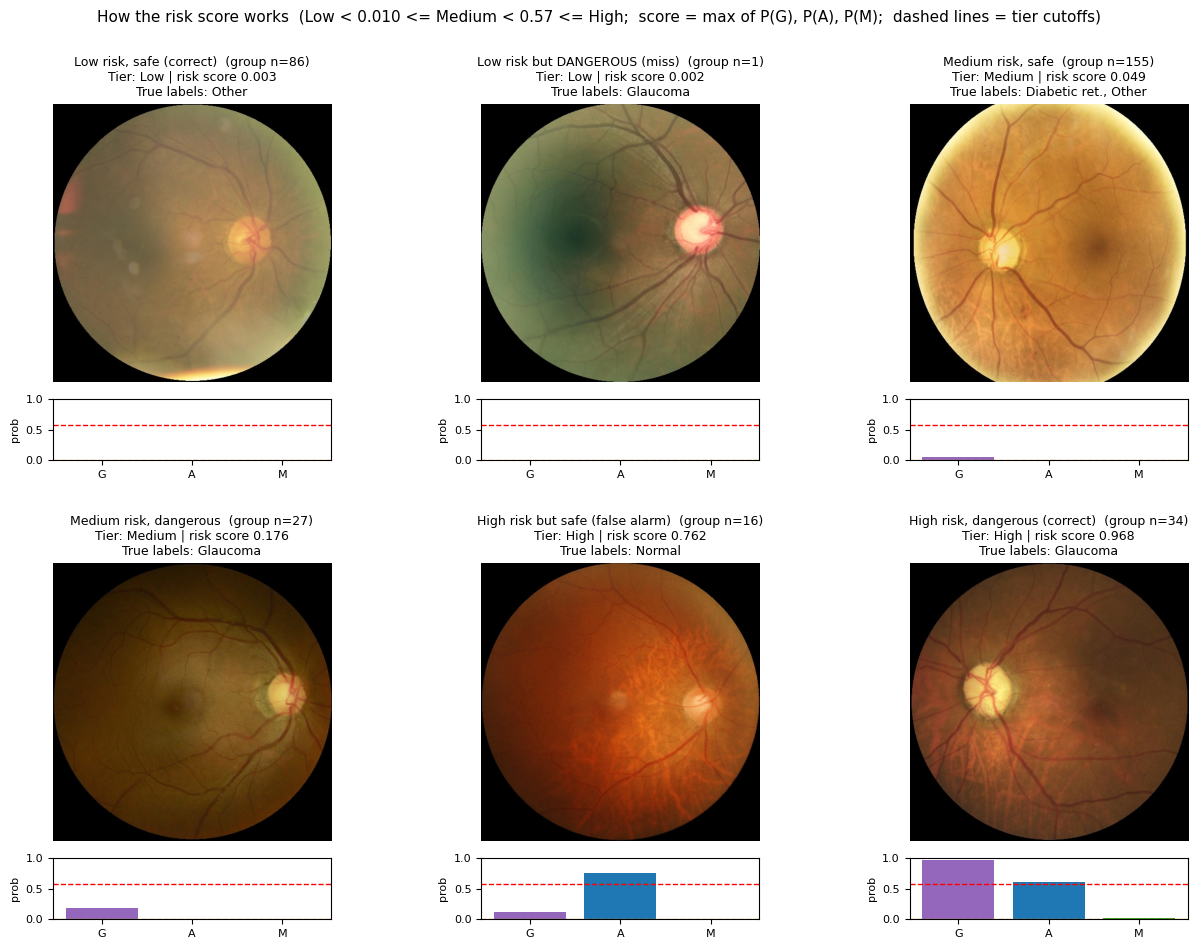

          File                            Group   Tier  Score  P(G)  P(A)  P(M)          True labels
 751_right.jpg         Low risk, safe (correct)    Low 0.0032 0.001 0.003 0.000                Other
1470_right.jpg    Low risk but DANGEROUS (miss)    Low 0.0018 0.002 0.000 0.000             Glaucoma
  964_left.jpg                Medium risk, safe Medium 0.0487 0.049 0.002 0.000 Diabetic ret., Other
1345_right.jpg           Medium risk, dangerous Medium 0.1762 0.176 0.001 0.001             Glaucoma
2923_right.jpg High risk but safe (false alarm)   High 0.7616 0.122 0.762 0.002               Normal
 1227_left.jpg   High risk, dangerous (correct)   High 0.9684 0.968 0.609 0.015             Glaucoma


In [ ]:

import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
DIR = '/content/drive/MyDrive/Thesis/saved_models/'
IMG = '/content/drive/MyDrive/Thesis/preprocessed_images'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
idx = [COLS.index(c) for c in POS]; LOW_SENS = 0.95

d = np.load(NPZ, allow_pickle=True)
Yall = d['y_true']; y = (Yall[:, idx].max(1) > 0).astype(int); clean = ~d['in_train']; fn = d['filename']
tune, test = np.where(~clean)[0], np.where(clean)[0]
P = d['C8_fusion']; s = P[:, idx].max(1)
grid = np.unique(np.concatenate([np.geomspace(1e-4, 0.5, 250), np.linspace(0.5, 0.99, 60)]))
t_hi = grid[int(np.argmax([f1_score(y[tune], s[tune] >= t, zero_division=0) for t in grid]))]
ok = [t for t in grid if (s[tune][y[tune] == 1] >= t).mean() >= LOW_SENS]; t_lo = min(max(ok) if ok else grid[0], t_hi)
tier = np.where(s >= t_hi, 'High', np.where(s >= t_lo, 'Medium', 'Low'))
full = {'N':'Normal','D':'Diabetic ret.','G':'Glaucoma','C':'Cataract','A':'AMD','H':'Hypertension','M':'Path. myopia','O':'Other'}
def label_text(i):
    t = [full[c] for c, v in zip(COLS, Yall[i]) if v > 0]; return ', '.join(t) if t else 'none'

groups = [('Low', 0, 'Low risk, safe (correct)'), ('Low', 1, 'Low risk but DANGEROUS (miss)'),
          ('Medium', 0, 'Medium risk, safe'), ('Medium', 1, 'Medium risk, dangerous'),
          ('High', 0, 'High risk but safe (false alarm)'), ('High', 1, 'High risk, dangerous (correct)')]
picked = []
for tr, lab, title in groups:
    cand = test[(tier[test] == tr) & (y[test] == lab)]
    if len(cand) == 0: print('No clean-test patient in group:', title); continue
    med = np.median(s[cand]); picked.append((int(cand[np.argmin(np.abs(s[cand] - med))]), title, len(cand)))

fig, axes = plt.subplots(2, 3, figsize=(13, 9.5))
for ax, (i, title, n) in zip(axes.ravel(), picked):
    ax.imshow(Image.open(os.path.join(IMG, fn[i])).convert('RGB')); ax.axis('off')
    ax.set_title(f"{title}  (group n={n})\nTier: {tier[i]} | risk score {s[i]:.3f}\nTrue labels: {label_text(i)}", fontsize=9)
    ins = ax.inset_axes([0.0, -0.28, 1.0, 0.22]); ins.bar(range(3), P[i, idx], color=['tab:purple', 'tab:blue', 'tab:green']); ins.set_xticks(range(3), POS)
    ins.axhline(t_hi, color='r', ls='--', lw=1); ins.axhline(t_lo, color='orange', ls='--', lw=1); ins.set_ylim(0, 1); ins.tick_params(labelsize=8)
    ins.set_ylabel('prob', fontsize=8)
for ax in axes.ravel()[len(picked):]: ax.axis('off')
fig.suptitle(f"How the risk score works  (Low < {t_lo:.3f} <= Medium < {t_hi:.2f} <= High;  score = max of P(G), P(A), P(M);  dashed lines = tier cutoffs)", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.subplots_adjust(hspace=0.65); plt.savefig(DIR + 'risk_examples.png', dpi=150, bbox_inches='tight'); plt.show()

rows = [{'File': fn[i], 'Group': t, 'Tier': tier[i], 'Score': round(float(s[i]), 4), 'P(G)': round(float(P[i, 2]), 3),
         'P(A)': round(float(P[i, 4]), 3), 'P(M)': round(float(P[i, 6]), 3), 'True labels': label_text(i)} for i, t, _ in picked]
print(pd.DataFrame(rows).to_string(index=False)); pd.DataFrame(rows).to_csv(DIR + 'risk_examples.csv', index=False)

In [ ]:
import json
from tensorflow.keras.models import load_model
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass
m = load_model('/content/drive/MyDrive/Thesis/saved_models/C8_final.keras', compile=False)

def parents(node):
    out = []
    def walk(x):
        if isinstance(x, dict):
            if 'keras_history' in x: out.append(x['keras_history'][0])
            for v in x.values(): walk(v)
        elif isinstance(x, list):
            if len(x) >= 3 and isinstance(x[0], str) and isinstance(x[1], int) and isinstance(x[2], int): out.append(x[0])
            else:
                for v in x: walk(v)
    walk(node); return list(dict.fromkeys(out))

print("INPUTS:", [(i.name, tuple(i.shape)) for i in m.inputs]); print("OUTPUT:", m.output.shape, "\n")
for L, cfg in zip(m.layers, m.get_config()['layers']):
    kind = type(L).__name__; src = parents(cfg.get('inbound_nodes', []))
    extra = ''
    if kind in ('Functional', 'Model'):
        four_d = [l.name for l in L.layers if len(getattr(l, 'output', None).shape) == 4] if True else []
        extra = f"  [nested: {len(L.layers)} layers | last 4D layer: {four_d[-1] if four_d else None} | out {tuple(L.output.shape)}]"
    print(f"{L.name:32s} {kind:22s} out={str(tuple(L.output.shape)):18s} <- {src}{extra}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
INPUTS: [('input_mobilenet', (None, 224, 224, 3)), ('input_efficientnet', (None, 224, 224, 3)), ('input_densenet', (None, 224, 224, 3)), ('input_resnet', (None, 224, 224, 3))]
OUTPUT: (None, 8) 

input_mobilenet                  InputLayer             out=(None, 224, 224, 3) <- []
input_efficientnet               InputLayer             out=(None, 224, 224, 3) <- []
input_densenet                   InputLayer             out=(None, 224, 224, 3) <- []
input_resnet                     InputLayer             out=(None, 224, 224, 3) <- []
extractor_MobileNetV2            Functional             out=(None, 1280)       <- []  [nested: 155 layers | last 4D layer: out_relu | out (None, 1280)]
extractor_EfficientNetB0         Functional             out=(None, 1280)       <- []  [nested: 239 layers | last 4D layer: top_activation | out (None, 1280)]
extractor_DenseNet121

# Grad-CAM

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
6 examples selected
Backbone feature maps exposed: {'extractor_MobileNetV2': (7, 7, 1280), 'extractor_EfficientNetB0': (7, 7, 1280), 'extractor_DenseNet121': (7, 7, 1024), 'extractor_ResNet50': (7, 7, 2048)}
Rebuild check: max |original - rebuilt| = 0.00e+00
Rebuild check also vs cached probabilities (C8): 0.0


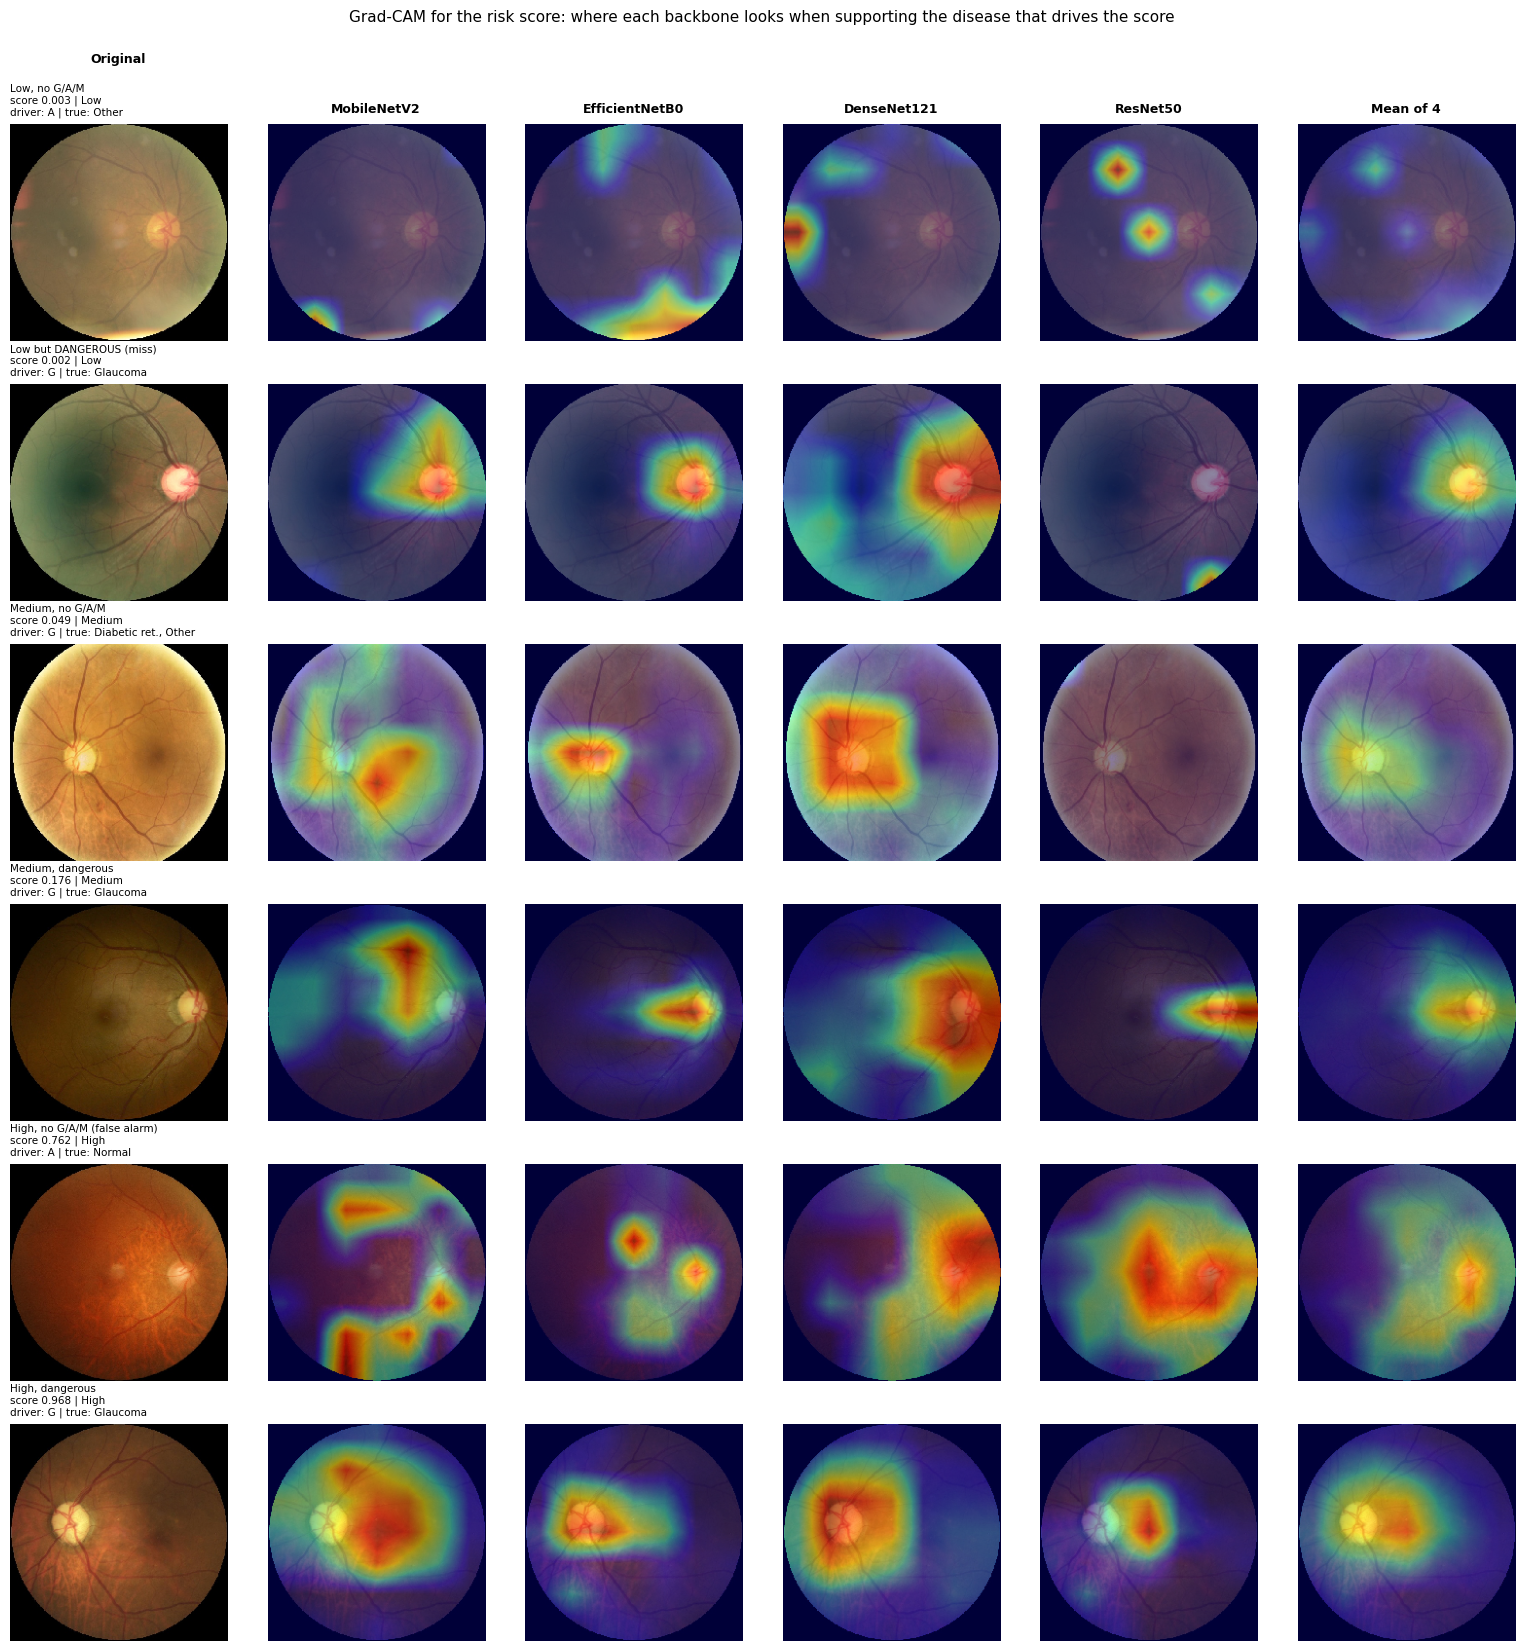

Saved /content/drive/MyDrive/Thesis/saved_models/risk_gradcam.png


In [ ]:

import os, numpy as np, tensorflow as tf, matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.layers import Input, InputLayer
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mob_pre
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_pre
from tensorflow.keras.applications.densenet import preprocess_input as den_pre
from tensorflow.keras.applications.resnet50 import preprocess_input as res_pre
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception: pass

NPZ = '/content/drive/MyDrive/Thesis/saved_models/val_probs.npz'
DIR = '/content/drive/MyDrive/Thesis/saved_models/'
IMG = '/content/drive/MyDrive/Thesis/preprocessed_images'
POS, COLS = ['G', 'A', 'M'], ['N','D','G','C','A','H','M','O']
idx = [COLS.index(c) for c in POS]; LOW_SENS = 0.95
PRE = [mob_pre, eff_pre, den_pre, res_pre]
BACKBONES = ['MobileNetV2', 'EfficientNetB0', 'DenseNet121', 'ResNet50']

d = np.load(NPZ, allow_pickle=True)
Yall = d['y_true']; y = (Yall[:, idx].max(1) > 0).astype(int); clean = ~d['in_train']; fn = d['filename']
tune, test = np.where(~clean)[0], np.where(clean)[0]
P = d['C8_fusion']; s = P[:, idx].max(1)
grid = np.unique(np.concatenate([np.geomspace(1e-4, 0.5, 250), np.linspace(0.5, 0.99, 60)]))
t_hi = grid[int(np.argmax([f1_score(y[tune], s[tune] >= t, zero_division=0) for t in grid]))]
ok = [t for t in grid if (s[tune][y[tune] == 1] >= t).mean() >= LOW_SENS]; t_lo = min(max(ok) if ok else grid[0], t_hi)
tier = np.where(s >= t_hi, 'High', np.where(s >= t_lo, 'Medium', 'Low'))
full = {'N':'Normal','D':'Diabetic ret.','G':'Glaucoma','C':'Cataract','A':'AMD','H':'Hypertension','M':'Path. myopia','O':'Other'}
def label_text(i):
    t = [full[c] for c, v in zip(COLS, Yall[i]) if v > 0]; return ', '.join(t) if t else 'none'
groups = [('Low', 0, 'Low, no G/A/M'), ('Low', 1, 'Low but DANGEROUS (miss)'), ('Medium', 0, 'Medium, no G/A/M'),
          ('Medium', 1, 'Medium, dangerous'), ('High', 0, 'High, no G/A/M (false alarm)'), ('High', 1, 'High, dangerous')]
picked = []
for tr, lab, title in groups:
    cand = test[(tier[test] == tr) & (y[test] == lab)]
    if len(cand): picked.append((int(cand[np.argmin(np.abs(s[cand] - np.median(s[cand])))]), title))
print(f"{len(picked)} examples selected")

m = load_model(DIR + 'C8_final.keras', compile=False)
def parents(L):
    node = L._inbound_nodes[0]; ts = getattr(node, 'input_tensors', None)
    if ts is None: ts = node.keras_inputs
    out = []
    for t in tf.nest.flatten(ts):
        h = t._keras_history; op = getattr(h, 'operation', None) or getattr(h, 'layer', None); out.append(op.name)
    return out

new_in = [Input(shape=(224, 224, 3), name=f"cam_in_{k}") for k in range(len(m.inputs))]
tensors, convs, k = {}, {}, 0
for L in m.layers:
    if isinstance(L, InputLayer): tensors[L.name] = new_in[k]; k += 1; continue
    ps = parents(L)
    if L.name.startswith('extractor_'):
        four_d = [l.name for l in L.layers if len(l.output.shape) == 4][-1]
        cm = Model(L.input, [L.get_layer(four_d).output, L.output])
        conv, pooled = cm(tensors[ps[0]]); tensors[L.name] = pooled; convs[L.name] = conv
    else:
        xs = [tensors[p] for p in ps]; tensors[L.name] = L(xs[0] if len(xs) == 1 else xs)
out_name = m.output._keras_history.operation.name if hasattr(m.output._keras_history, 'operation') else m.output._keras_history.layer.name
cam_model = Model(new_in, list(convs.values()) + [tensors[out_name]])
print("Backbone feature maps exposed:", {n: tuple(v.shape[1:]) for n, v in convs.items()})

def load(f): return keras_image.img_to_array(keras_image.load_img(os.path.join(IMG, f), target_size=(224, 224))).astype(np.float32)
raw = np.stack([load(fn[i]) for i, _ in picked]); X = [tf.constant(np.stack([pre(a.copy()) for a in raw])) for pre in PRE]
ref = m(X, training=False).numpy(); got = cam_model(X, training=False)[-1].numpy()
diff = np.abs(ref - got).max(); print(f"Rebuild check: max |original - rebuilt| = {diff:.2e}")
assert diff < 1e-3, "Rebuilt model does not match the original - stop and send me this message plus the inspection output."
print("Rebuild check also vs cached probabilities (C8):", np.abs(got[:, idx] - P[[i for i, _ in picked]][:, idx]).max().round(4))

def cams_for(j, xs):
    with tf.GradientTape() as tape:
        for x in xs: tape.watch(x)
        res = cam_model(xs, training=False); cv, o = res[:-1], res[-1]; tgt = o[:, j]
    gr = tape.gradient(tgt, cv); maps = []
    for c, g in zip(cv, gr):
        w = tf.reduce_mean(g, axis=(1, 2), keepdims=True); cam = tf.nn.relu(tf.reduce_sum(w * c, axis=-1, keepdims=True))
        cam = tf.image.resize(cam, (224, 224), method='bilinear')[..., 0].numpy(); maps.append(cam)
    return maps

n = len(picked); drivers = [int(np.argmax(got[r, idx])) for r in range(n)]
maps_all = np.zeros((4, n, 224, 224), dtype=np.float32)
for r in range(n):
    xs = [x[r:r+1] for x in X]; mp = cams_for(idx[drivers[r]], xs)
    for b in range(4): maps_all[b, r] = mp[b][0]
def norm(a): a = a - a.min(); return a / a.max() if a.max() > 0 else a
fund_mask = (raw.mean(-1) > 12).astype(np.float32)

cols = ['Original'] + BACKBONES + ['Mean of 4']
fig, ax = plt.subplots(n, len(cols), figsize=(2.6 * len(cols), 2.8 * n))
ax = np.atleast_2d(ax)
for r, (i, title) in enumerate(picked):
    heats = [norm(maps_all[b, r]) * fund_mask[r] for b in range(4)]; heats.append(np.mean(heats, axis=0))
    ax[r, 0].imshow(raw[r].astype('uint8'))
    ax[r, 0].set_title(f"{title}\nscore {s[i]:.3f} | {tier[i]}\ndriver: {POS[drivers[r]]} | true: {label_text(i)}", fontsize=7.5, loc='left')
    for c, h in enumerate(heats, start=1):
        ax[r, c].imshow(raw[r].astype('uint8')); ax[r, c].imshow(h, cmap='jet', alpha=0.45, vmin=0, vmax=1)
    for c in range(len(cols)):
        ax[r, c].axis('off')
        if r == 0: ax[r, c].text(0.5, 1.28 if c == 0 else 1.05, cols[c], transform=ax[r, c].transAxes, ha='center', fontsize=9, fontweight='bold')
fig.suptitle('Grad-CAM for the risk score: where each backbone looks when supporting the disease that drives the score', fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.savefig(DIR + 'risk_gradcam.png', dpi=140, bbox_inches='tight'); plt.show()
print('Saved', DIR + 'risk_gradcam.png')